# GenAI Retrieval and Memory Patterns

This notebook covers the architecture and engineering of Retrieval-Augmented Generation (RAG) systems — from the core pipeline through hybrid search, query transformation, context and memory management, and production-grade scaling with async processing and caching.

## Table of Contents

1. [Module 01: Building Scalable RAG Architectures](#module-01)
2. [Module 02: Optimizing and Scaling RAG for Enterprise Systems](#module-02)
3. [Module 03: Optimizing Context and Memory Management](#module-03)
4. [Module 04: Caching, Optimizing, and Monitoring Performance](#module-04)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

---
<a id="module-01"></a>
## Module 01: Building Scalable RAG Architectures

_Covers LLM limitations that motivate RAG, the five-stage RAG pipeline, vector embeddings, document chunking strategies, hybrid search, and query transformation with re-ranking._

### Why Context and Memory Matter

Large language models have fundamental limitations that RAG addresses:

- **Lack of real-time knowledge** — training data has a fixed cutoff date
- **No memory awareness** — each request is stateless by default
- **Limited context window** — only a fixed number of tokens can be processed at once
- **Lack of understanding and common sense** — models can hallucinate or reason incorrectly

#### Memory

> Memory is the faculty by which data or information is encoded, stored, and retrieved when needed.

Memory benefits for AI systems:
- Learning and improving over interactions
- Retaining context across a session or across sessions
- Adapting and personalising responses to the user

#### Context

> In NLP, *context* refers to both the external circumstances (temporal, spatial, social, cultural) under which a behaviour or event occurs, and the surrounding text that gives meaning to a word or phrase.

Together, memory and context are what make RAG-based systems feel grounded and coherent.

### The 5 Stages Within RAG

Every RAG system passes through five sequential stages:


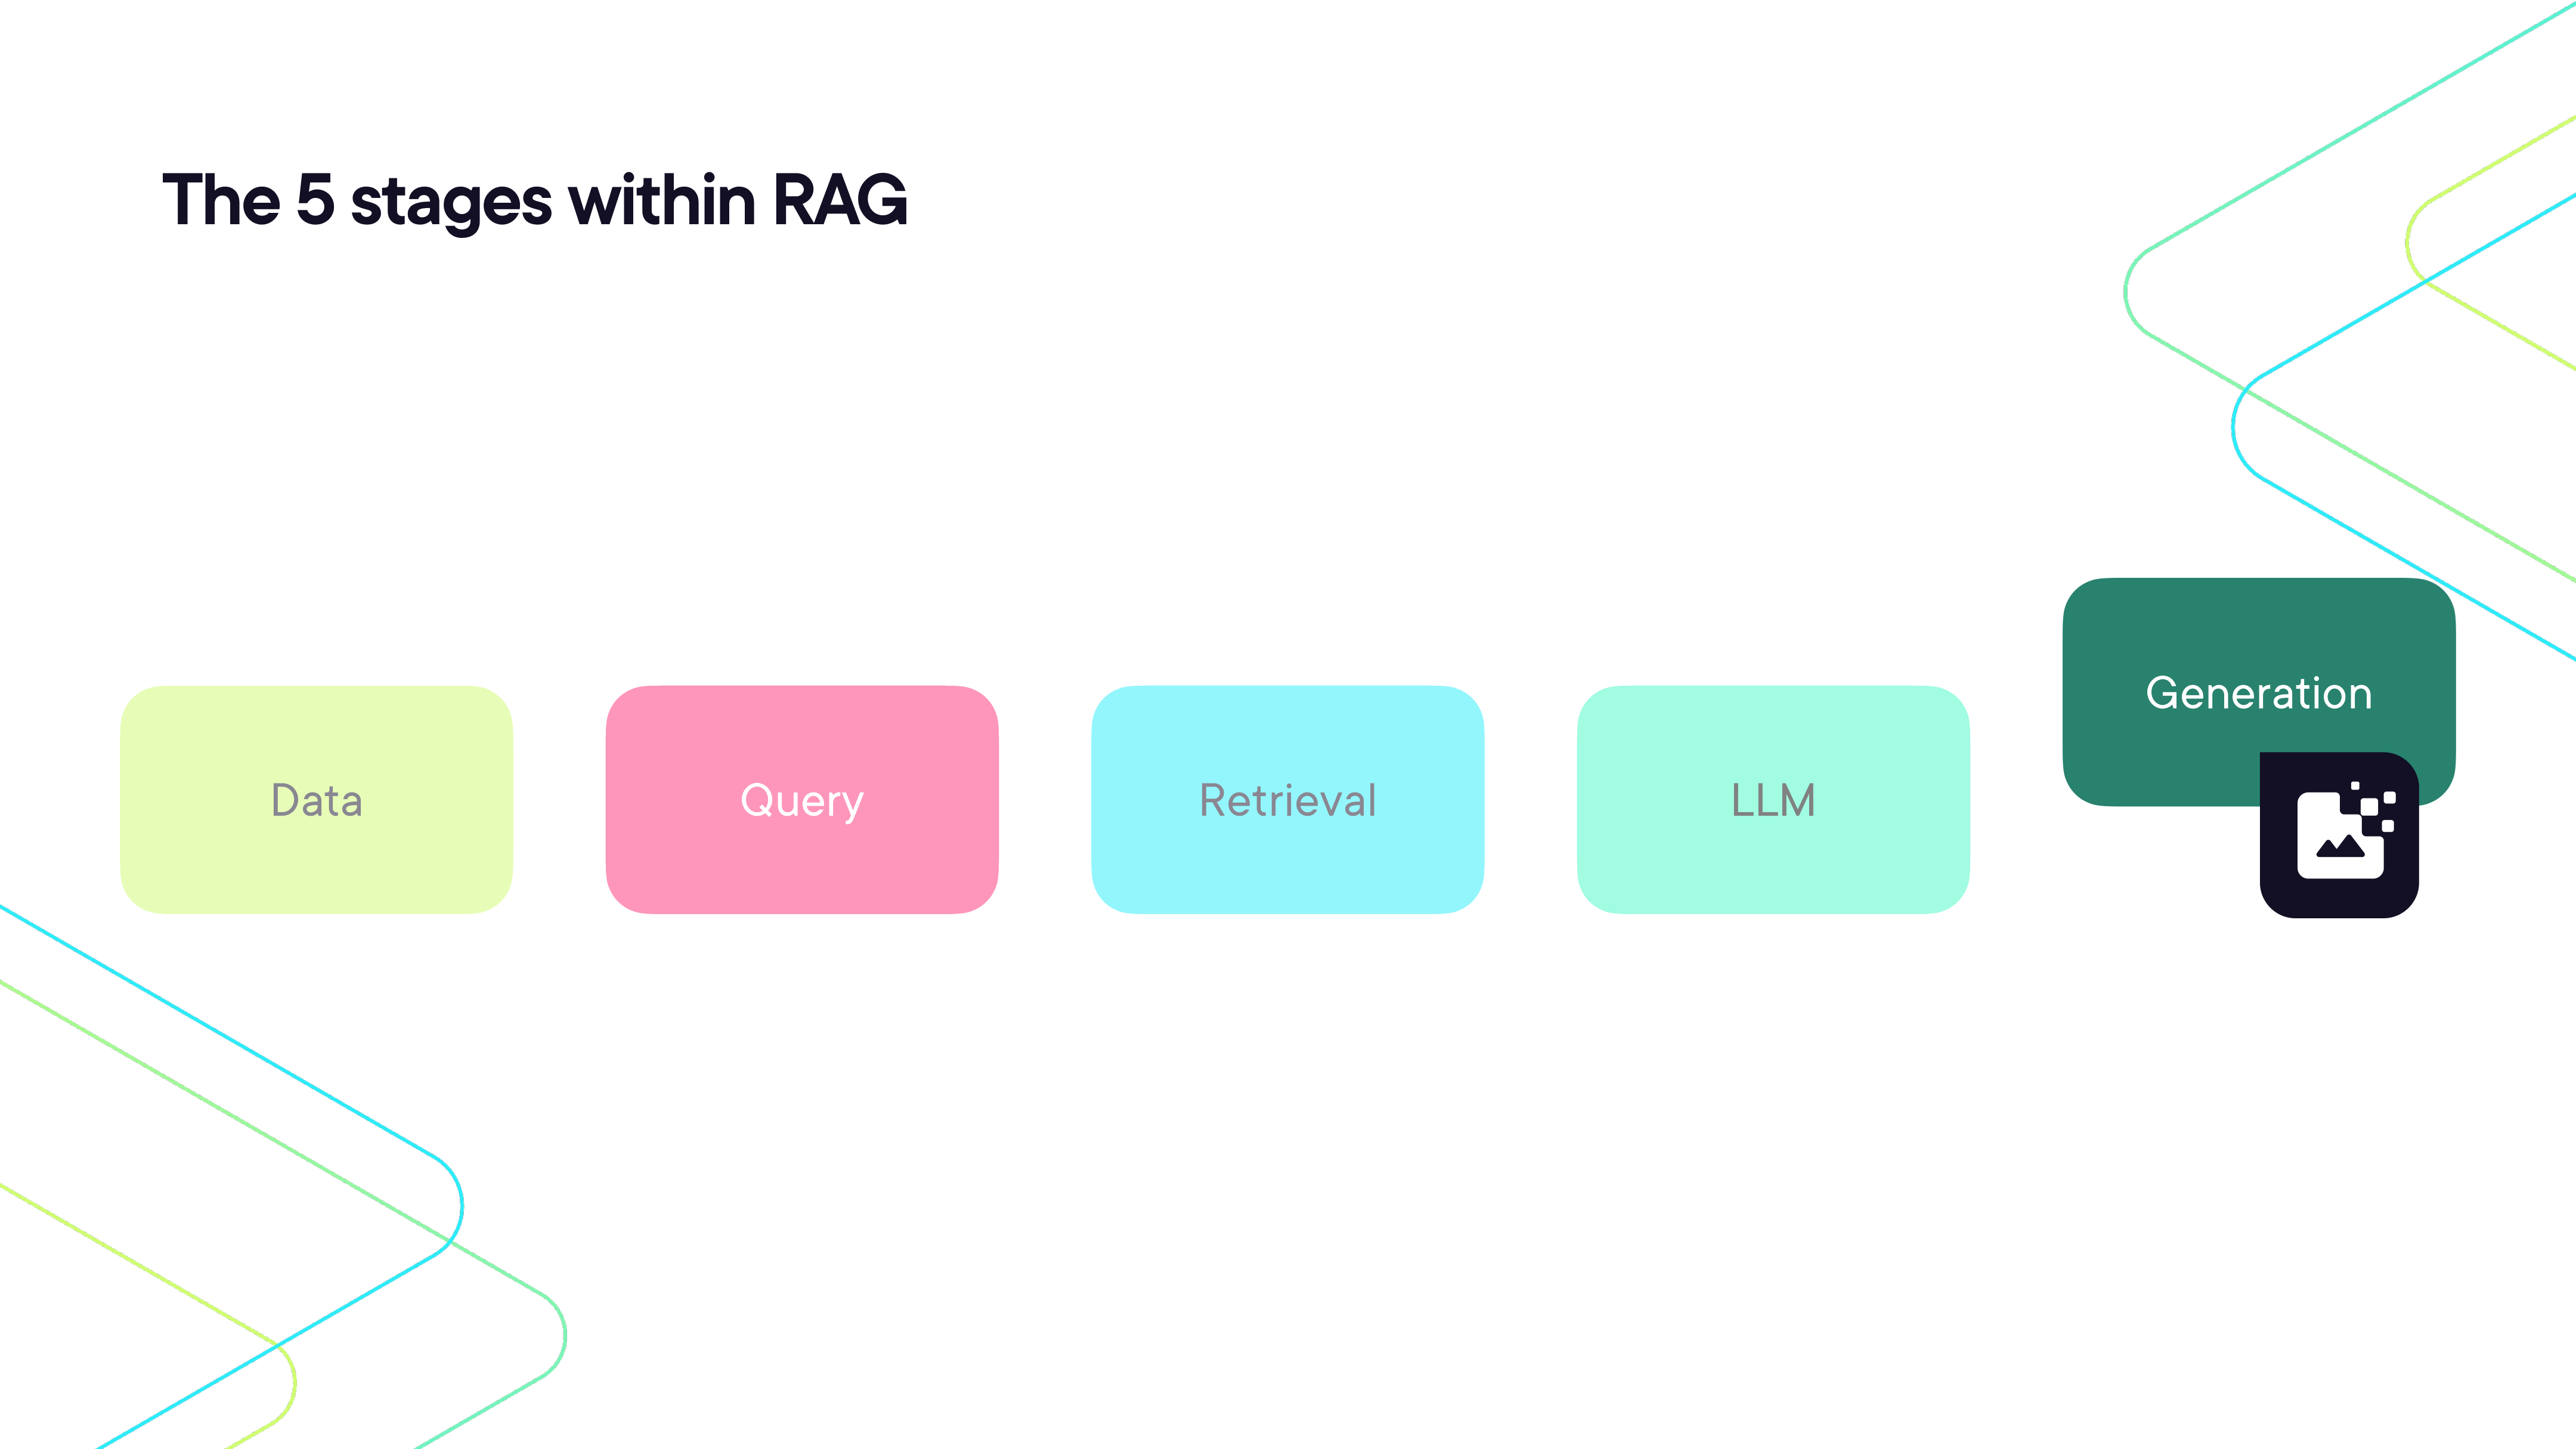

In [2]:
render_diagram(Path("assets/01-rag-five-stages-pipeline.png"))

| Stage | Responsibility |
|---|---|
| **Data** | Ingest, parse, chunk, and embed documents into a vector store |
| **Query** | Accept the user's question; optionally transform or expand it |
| **Retrieval** | Find the most relevant chunks using vector or keyword search |
| **LLM** | Receive the query + retrieved context; generate an answer |
| **Generation** | Return the augmented, grounded response to the user |

#### LLM-only vs. RAG with context

Without retrieval, a query goes straight to the LLM and the response is limited to training knowledge. With RAG, relevant documents are fetched first and injected into the prompt as context, grounding the response in external knowledge.


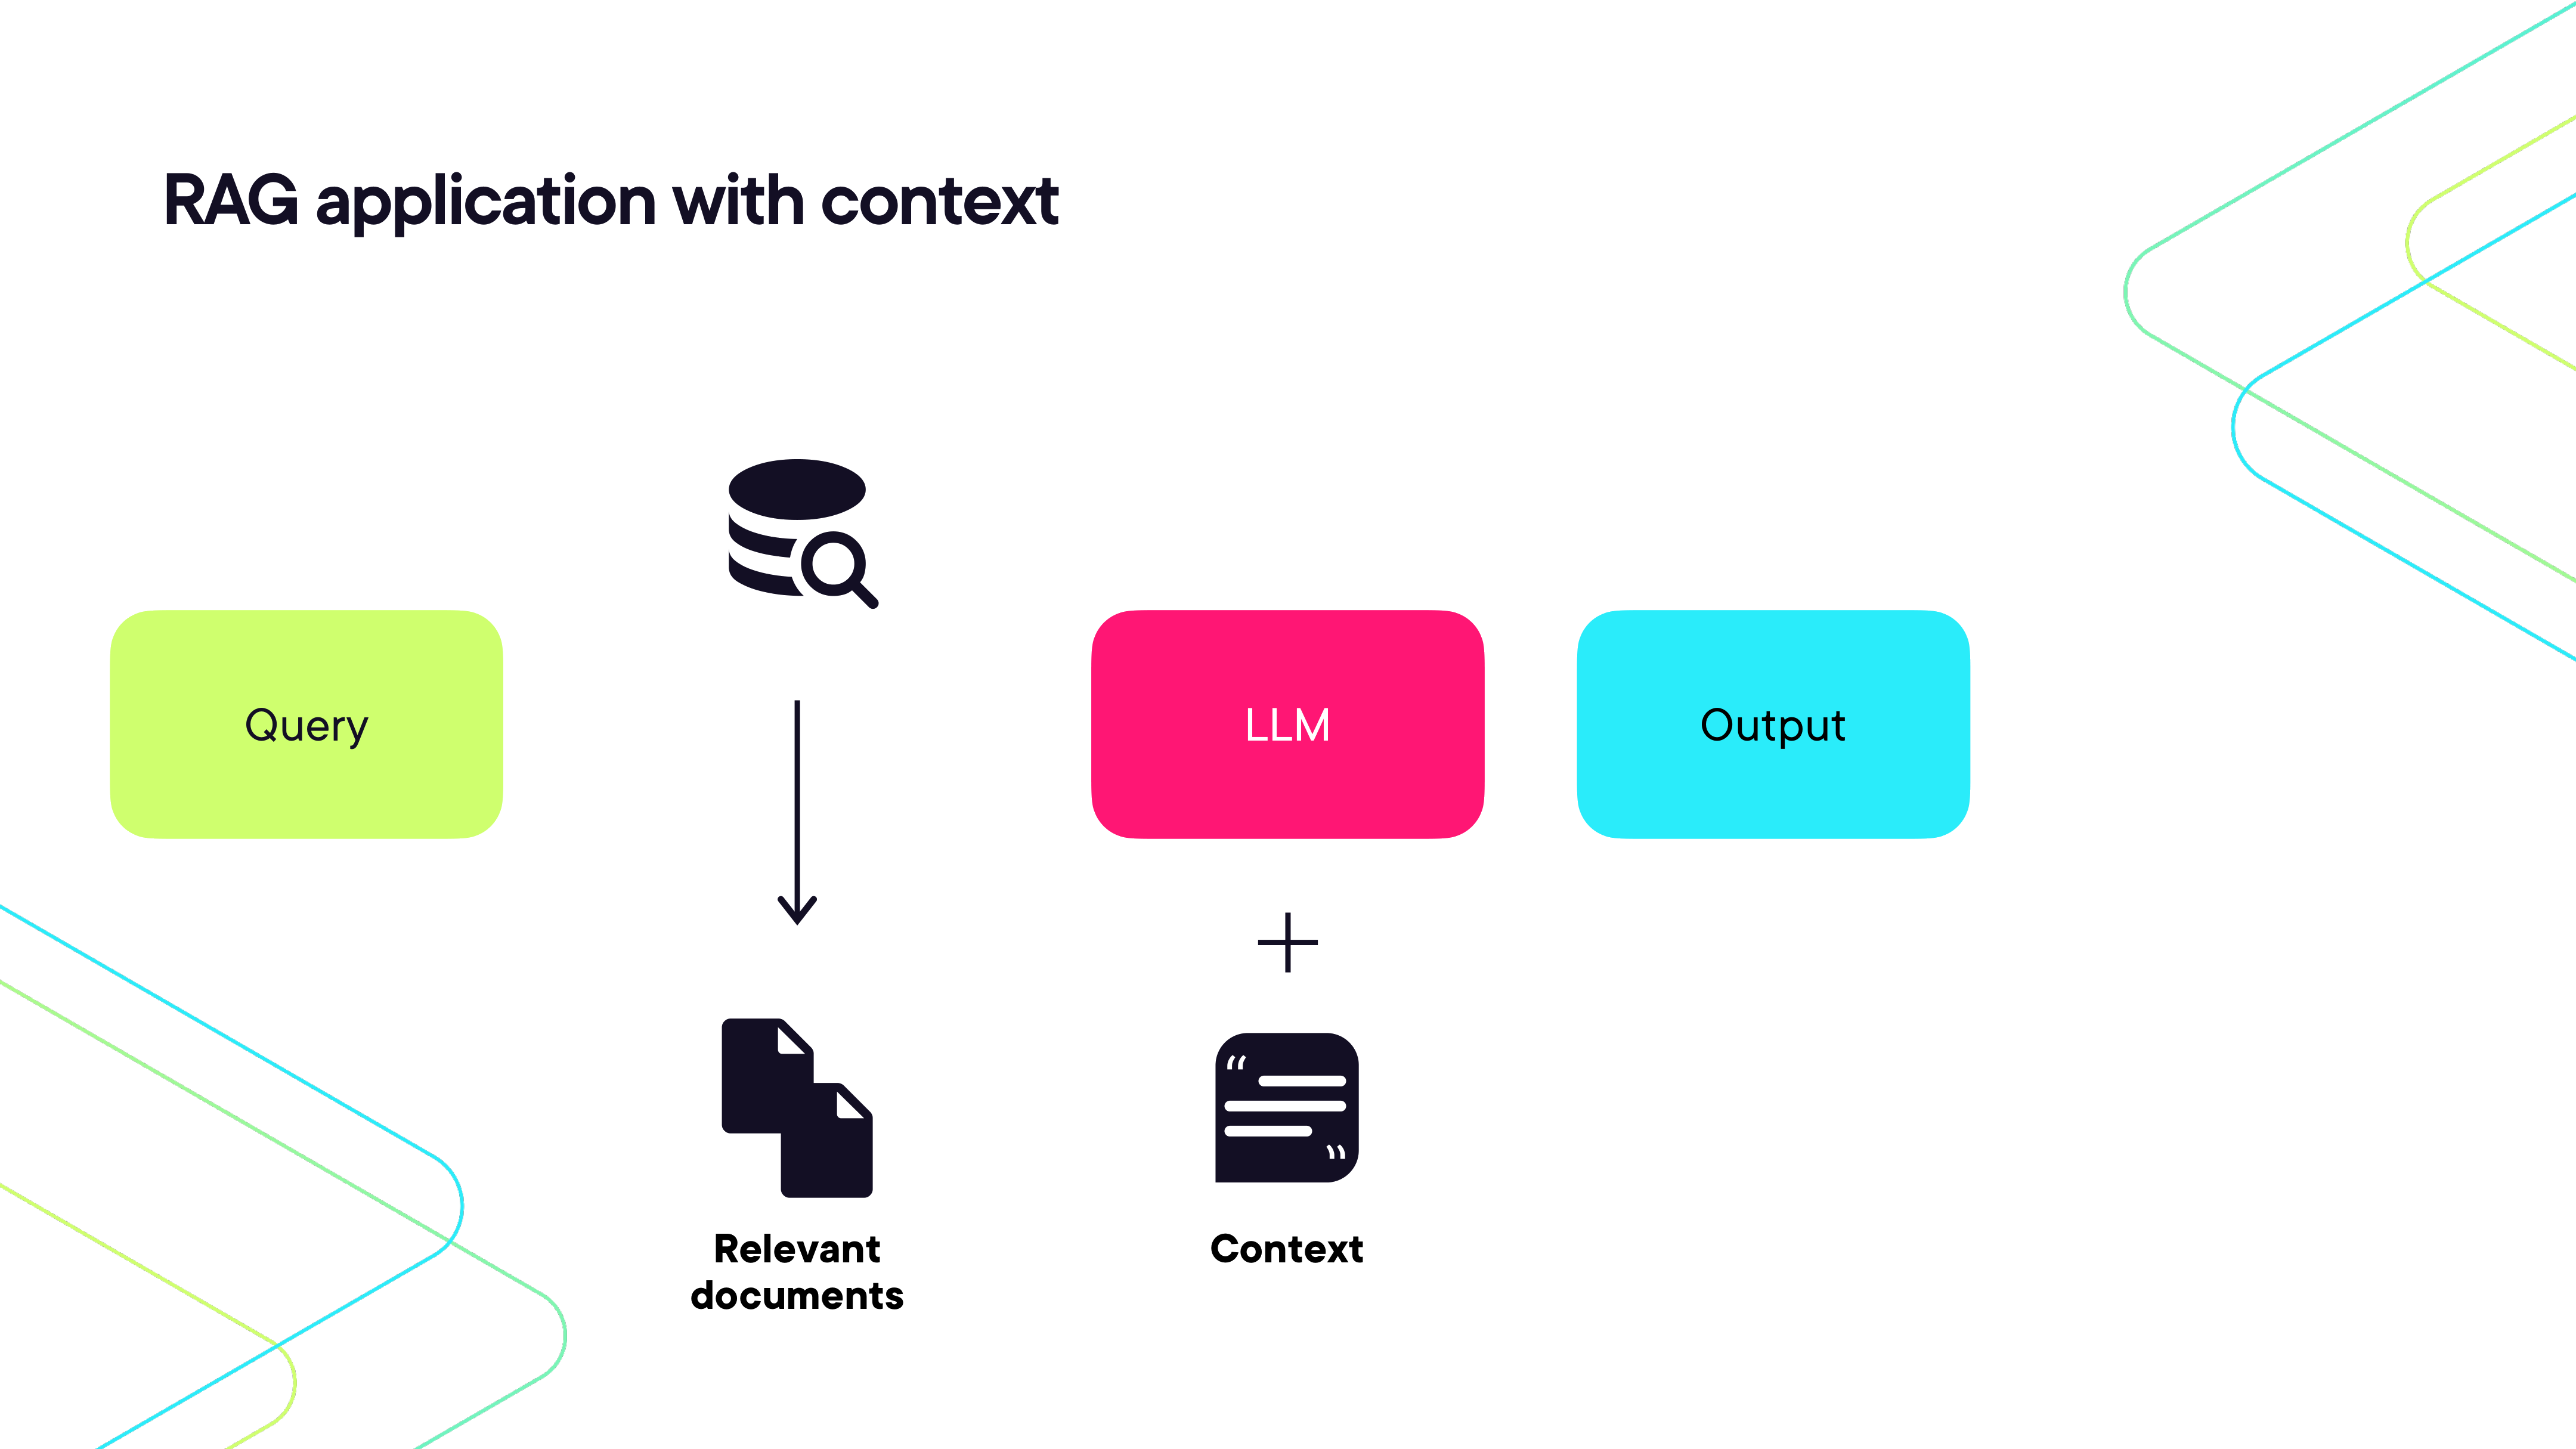

In [3]:
render_diagram(Path("assets/02-rag-application-with-context.png"))

The full augmented flow adds a **Prompt** layer: the retrieved documents are assembled with the query into a structured prompt before being passed to the LLM, producing an **Augmented Output**.


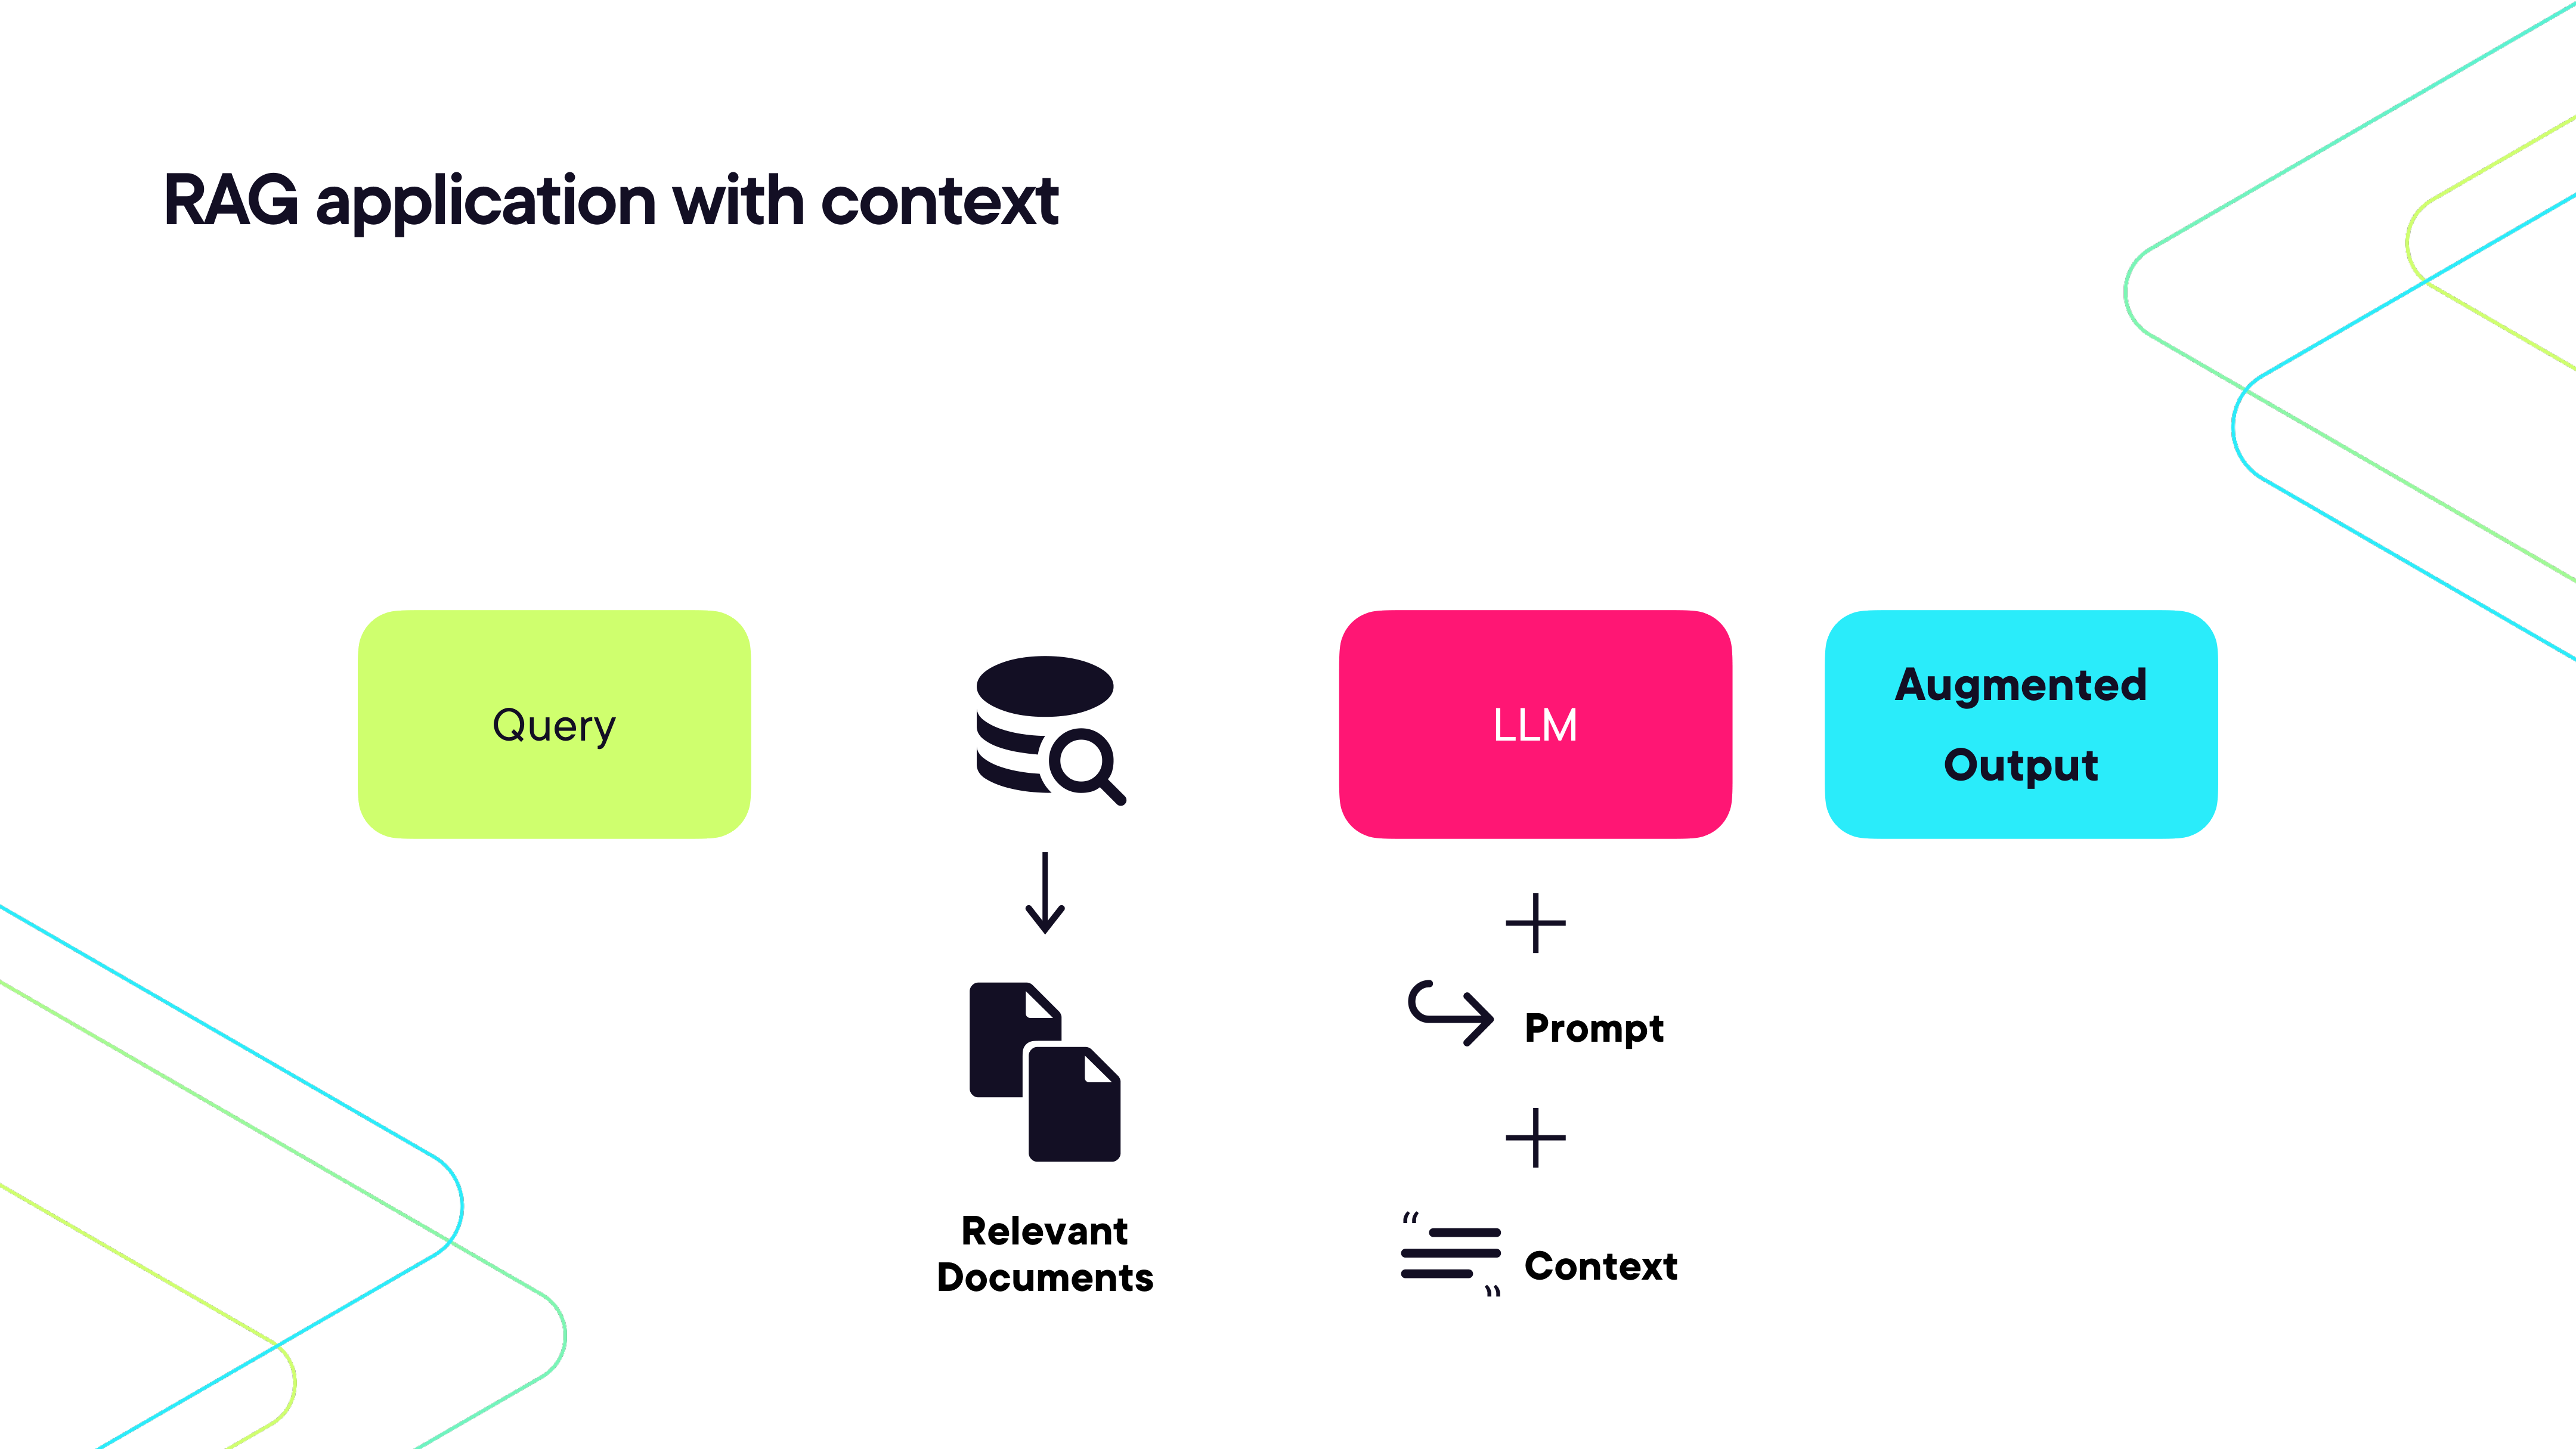

In [4]:
render_diagram(Path("assets/03-rag-with-embeddings-flow.png"))

### Demo: Basic RAG Query Engine (exercises 1.1–1.2)

A step-by-step walkthrough of building a minimal RAG query engine with LlamaIndex: loading documents, generating embeddings with OpenAI, storing vectors, and querying with a `VectorStoreIndex`.

**Prerequisites:** Python 3.10+, basic LLM familiarity, OpenAI API key  
**Stack:** LlamaIndex · OpenAI · LangSmith

See [`01-scalable-rag-demos/1.1/`](01-scalable-rag-demos/1.1/) and [`01-scalable-rag-demos/1.2/`](01-scalable-rag-demos/1.2/) for the full projects (each has a `start/` and `end/` state).

### Vector Embeddings

Embeddings are floating-point vectors that represent the semantic meaning of text. Key properties:

- Each text chunk is encoded into a high-dimensional vector (e.g. 1536 dimensions for `text-embedding-ada-002`)
- The **distance** between two vectors measures their semantic relatedness — closer vectors are more similar in meaning
- This enables semantic search: retrieve documents by _meaning_, not just by exact word match

### Document Chunking

Before embedding, documents are split into smaller chunks so that retrieved context fits within the LLM's token window and is as relevant as possible.

Chunking feeds into both the **Data** stage (generating per-chunk embeddings) and the **Context** stage (assembling retrieved chunks for the LLM prompt).

#### Advanced chunking strategies

- **Dynamic chunk selection** — adapt the number and selection of retrieved chunks to each query, rather than always using a fixed top-k
- **Relevance-based truncation** — keep only the most relevant portions of retrieved content, trimming the rest to stay within token limits
- **Summarization** — compress multiple retrieved chunks into a shorter, coherent representation before passing to the LLM

**Benefits:**
- More precise source attribution
- Improved context quality for LLM generation
- Higher retrieval accuracy
- Better answer quality

### Demo: Chunking Strategies and Context Management (exercises 1.3–1.5)

Compares document splitters and context management techniques: fixed-size chunking, recursive splitting, dynamic chunk selection, relevance-based truncation, and context summarization.

See [`01-scalable-rag-demos/1.3/`](01-scalable-rag-demos/1.3/), [`01-scalable-rag-demos/1.4/`](01-scalable-rag-demos/1.4/), and [`01-scalable-rag-demos/1.5/`](01-scalable-rag-demos/1.5/) for the full projects.

### Hybrid Search and Multi-Stage Retrieval

Production RAG systems combine multiple retrieval strategies:


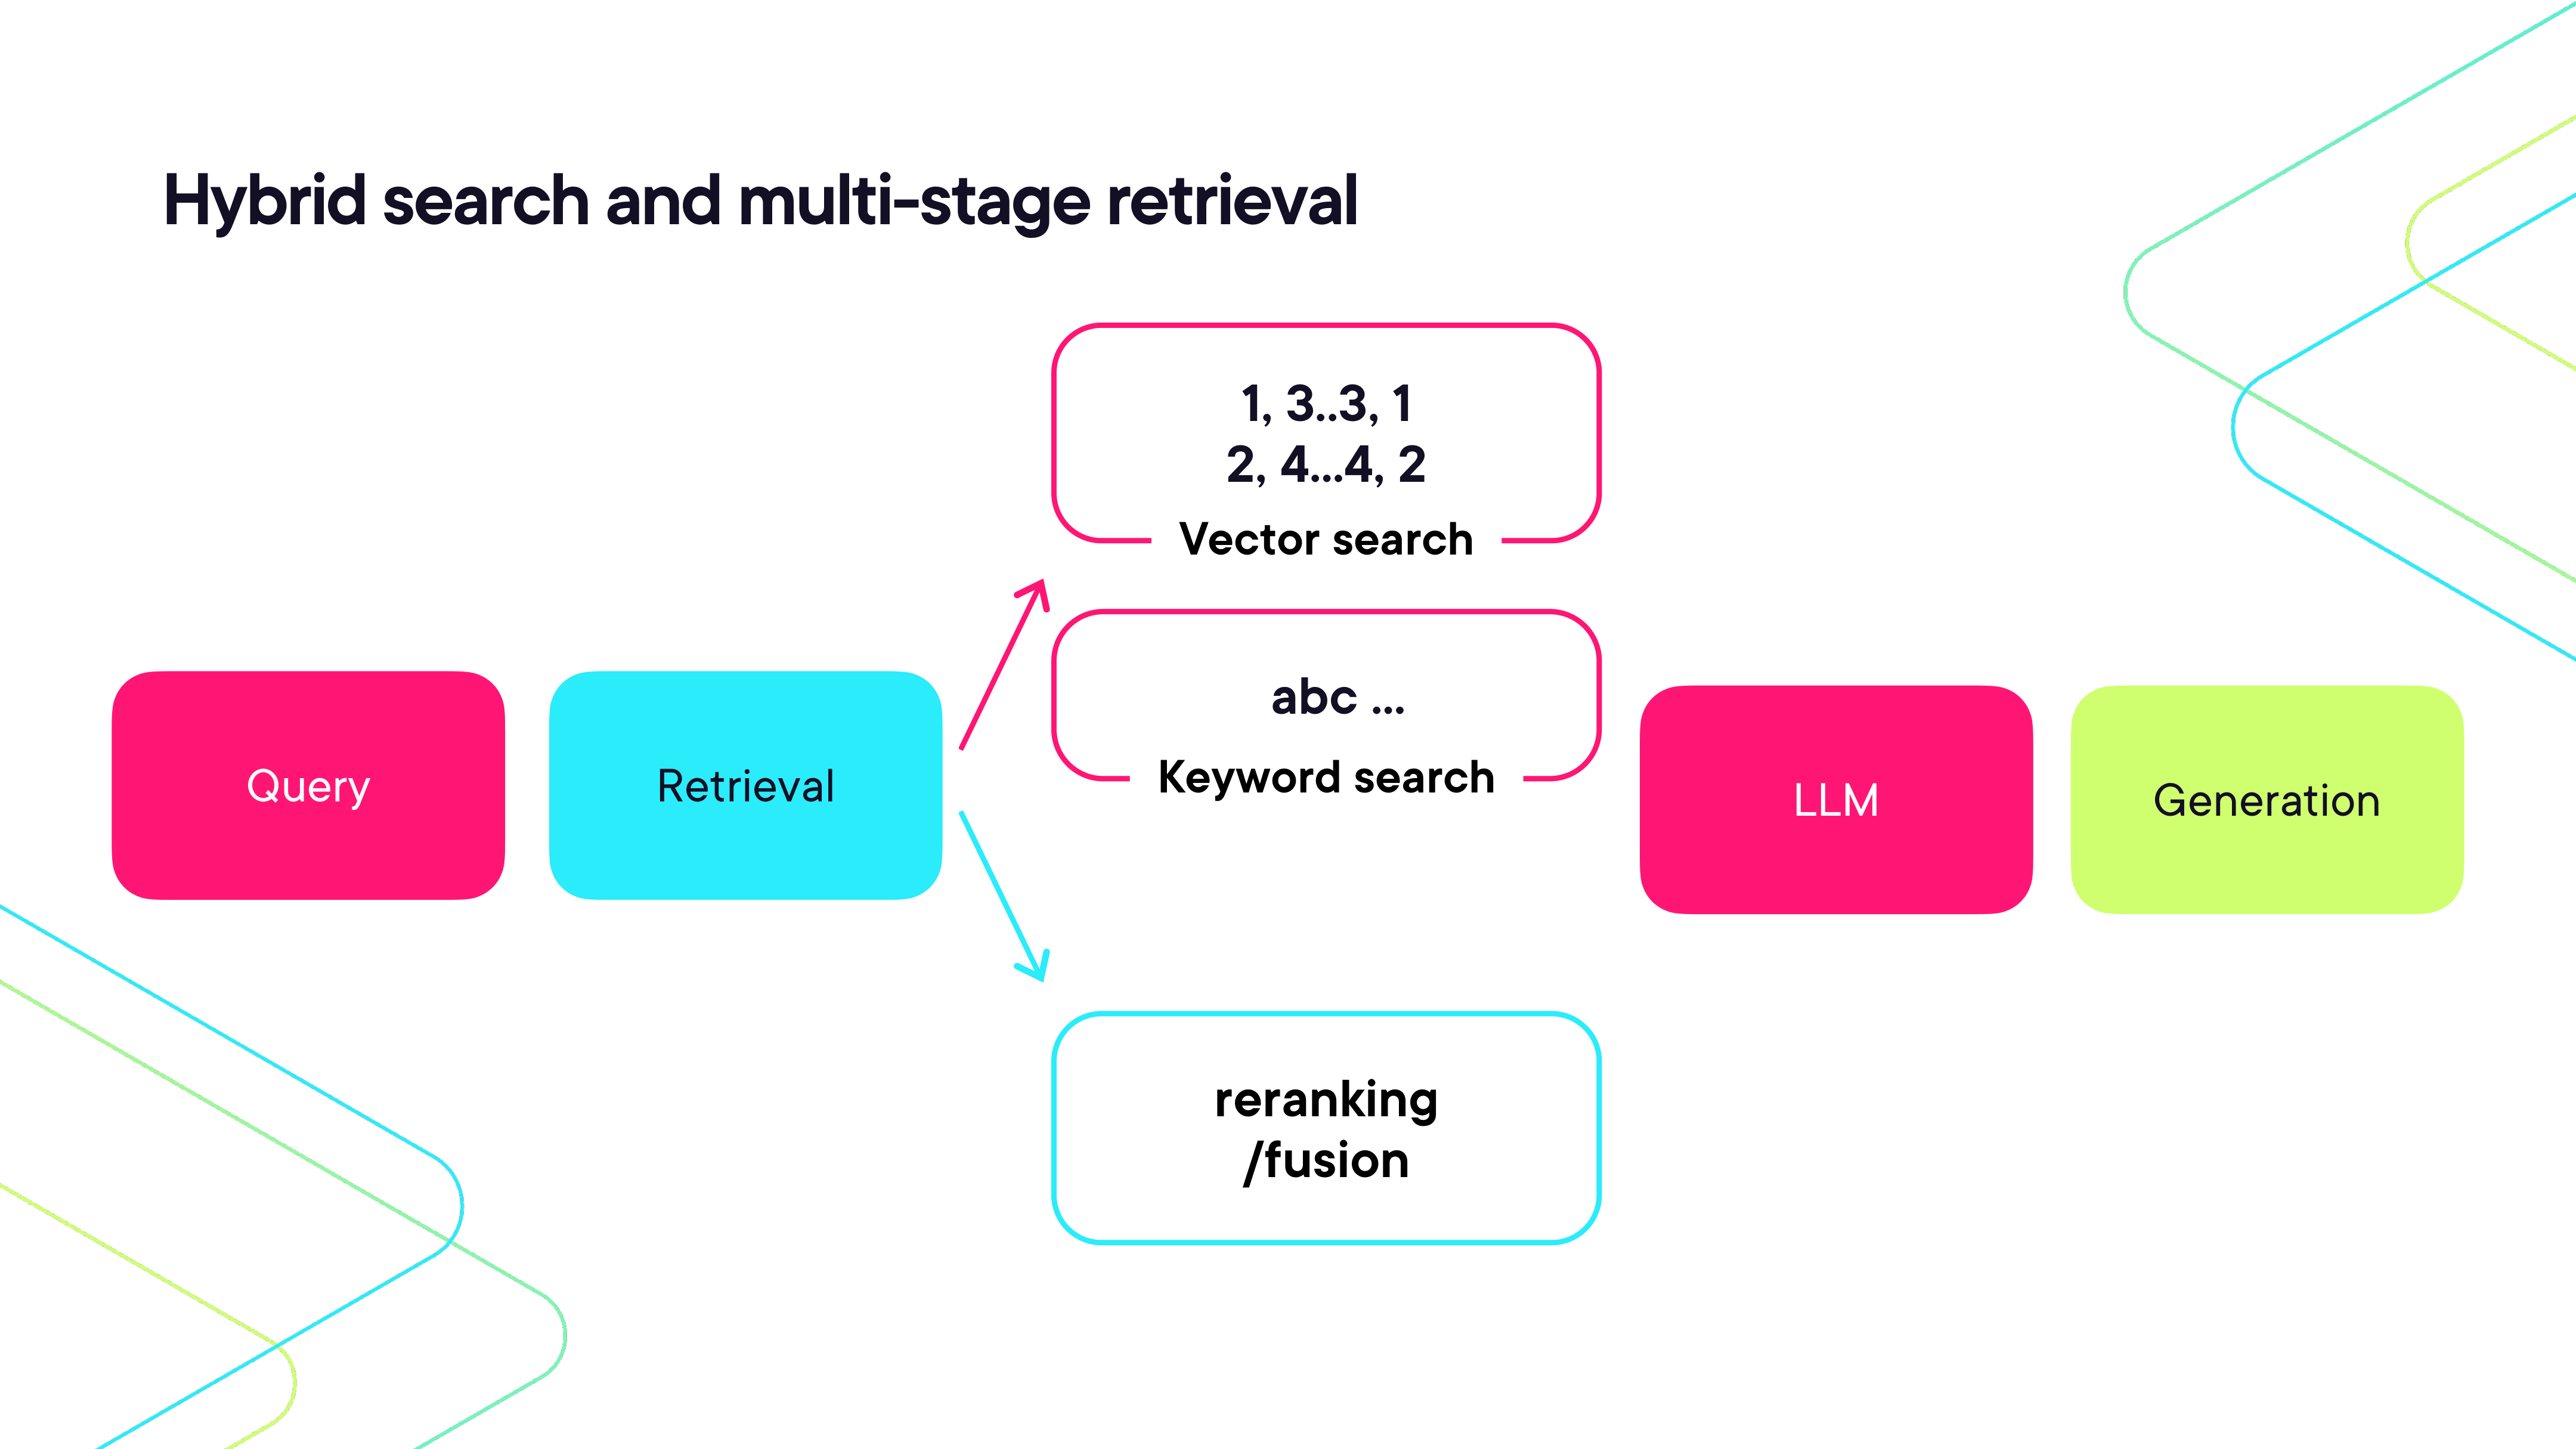

In [5]:
render_diagram(Path("assets/04-hybrid-search-pipeline.png"))

#### Keyword Search (BM25)

Retrieves documents based on **exact or lexical matches** between query terms and document terms. Fast, interpretable, and effective for precise terminology.

#### Vector Search (Dense Retrieval)

Retrieves documents based on **semantic similarity** using embeddings. Captures meaning and handles paraphrasing, synonyms, and conceptual similarity.

#### Sparse vs. Dense Retrieval

| | Sparse (BM25) | Dense (Vector) |
|---|---|---|
| Matching | Exact word matching | Semantic relatedness |
| Good for | Precise terms, codes, names | Natural language, synonyms |

#### Top-k Retrieval

Retrieves the *k* most relevant documents or chunks based on a scoring function. The score combines results from both retrievers.

#### Re-ranking

After initial retrieval, retrieved documents are **re-ordered** using a more powerful cross-encoder model to improve precision before passing context to the LLM.

### Query Transformation and Results Re-ranking

The query stage can be enriched before retrieval:


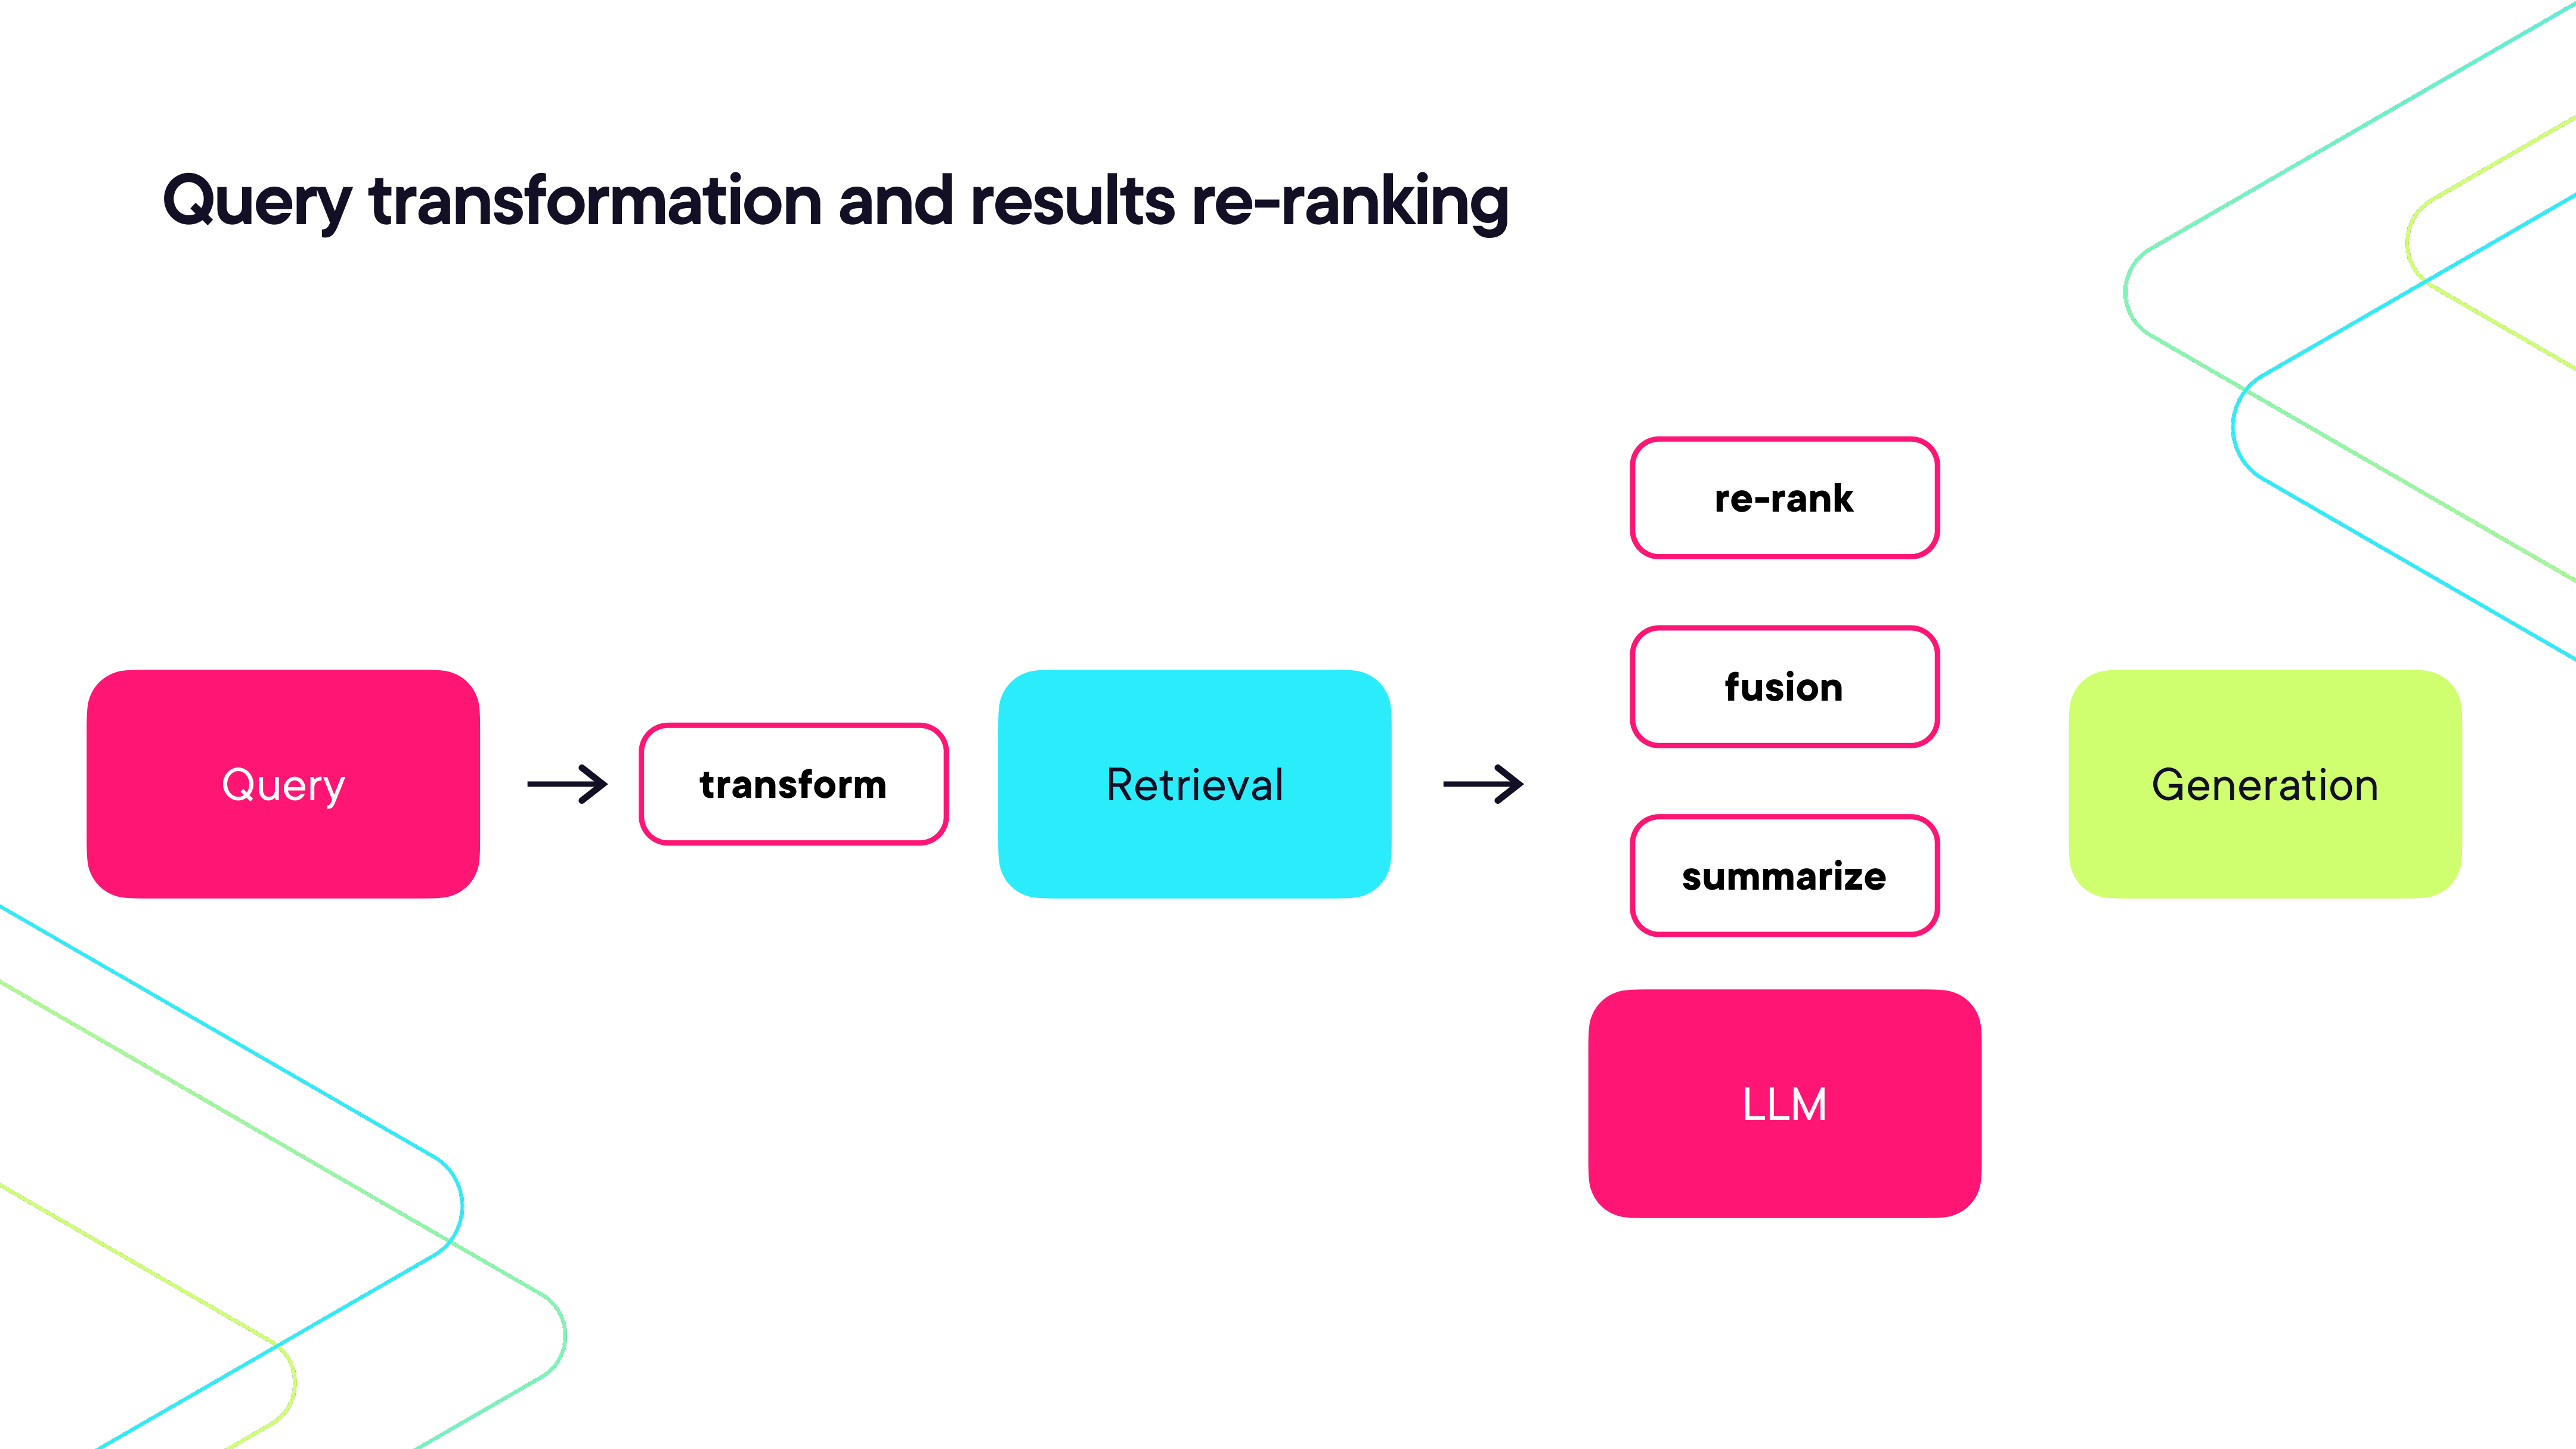

In [6]:
render_diagram(Path("assets/05-query-transformation-reranking.png"))

#### Query Transformation

Converts a query into an improved and rewritten version before retrieval. Improves retrieval by rewriting or expanding the original query.

**Example:**
- Original: *"What is Paul Graham known for?"*
- Transformed: *"Provide a precise and factual answer: What is Paul Graham known for?"*

After retrieval, results pass through **re-rank**, **fusion**, and **summarize** steps before the LLM generates the final answer.

### Demo: Hybrid Search and Query Transformation (exercises 1.4–1.5)

Demonstrates fast multi-stage retrieval with re-ranking pipelines: applying query expansion and rewriting to improve document retrieval, then combining BM25 + vector search results with fusion and cross-encoder reranking.

See [`01-scalable-rag-demos/1.4/`](01-scalable-rag-demos/1.4/) and [`01-scalable-rag-demos/1.5/`](01-scalable-rag-demos/1.5/) for the full projects.

---
<a id="module-02"></a>
## Module 02: Optimizing and Scaling RAG for Enterprise Systems

_Moves from a basic RAG pipeline to a production-ready, adaptive system with query classification, hybrid retrieval with RRF, and context assembly._

### Going from Basics to Production-Ready

A basic RAG pipeline — Data → Query → Retrieval → LLM → Generation — works for prototypes, but production systems need each stage to be significantly more sophisticated.

#### Query Stage: Transformation, Decomposition and Classification

Raw user queries are processed through two steps before retrieval:

**Query → Transform → Classification**

- **Transform** — rewrite, expand, or decompose the query into sub-questions
- **Classification** — route the transformed query to the appropriate retrieval strategy

Common techniques include HyDE (Hypothetical Document Embeddings), step-back prompting, and query decomposition for multi-hop questions.

#### Retrieval Stage: Adaptive Retrieval with BM25 + Vector + RRF

**Retrieval → BM25Retriever + VectorRetriever → RRF**

Both sparse (BM25) and dense (vector) retrievers run in parallel. Their ranked result lists are merged using **Reciprocal Rank Fusion (RRF)**, which combines rankings without needing score normalisation.

#### LLM Generation Stage: Context Optimization and Assembly

**Summarization/pruning → Context Assembly → LLM Generation**

Retrieved chunks are pruned and summarised to fit the context window, then assembled into a structured prompt before LLM generation.

### Adaptive Retrieval with RRF

Reciprocal Rank Fusion merges ranked lists from multiple retrievers. For each document, RRF computes:

```
RRF_score(d) = Σ  1 / (k + rank_i(d))
```

where `k` is a smoothing constant (typically 60) and `rank_i(d)` is the document's position in retriever `i`'s result list. Documents that rank highly in multiple retrievers receive the highest fused scores.


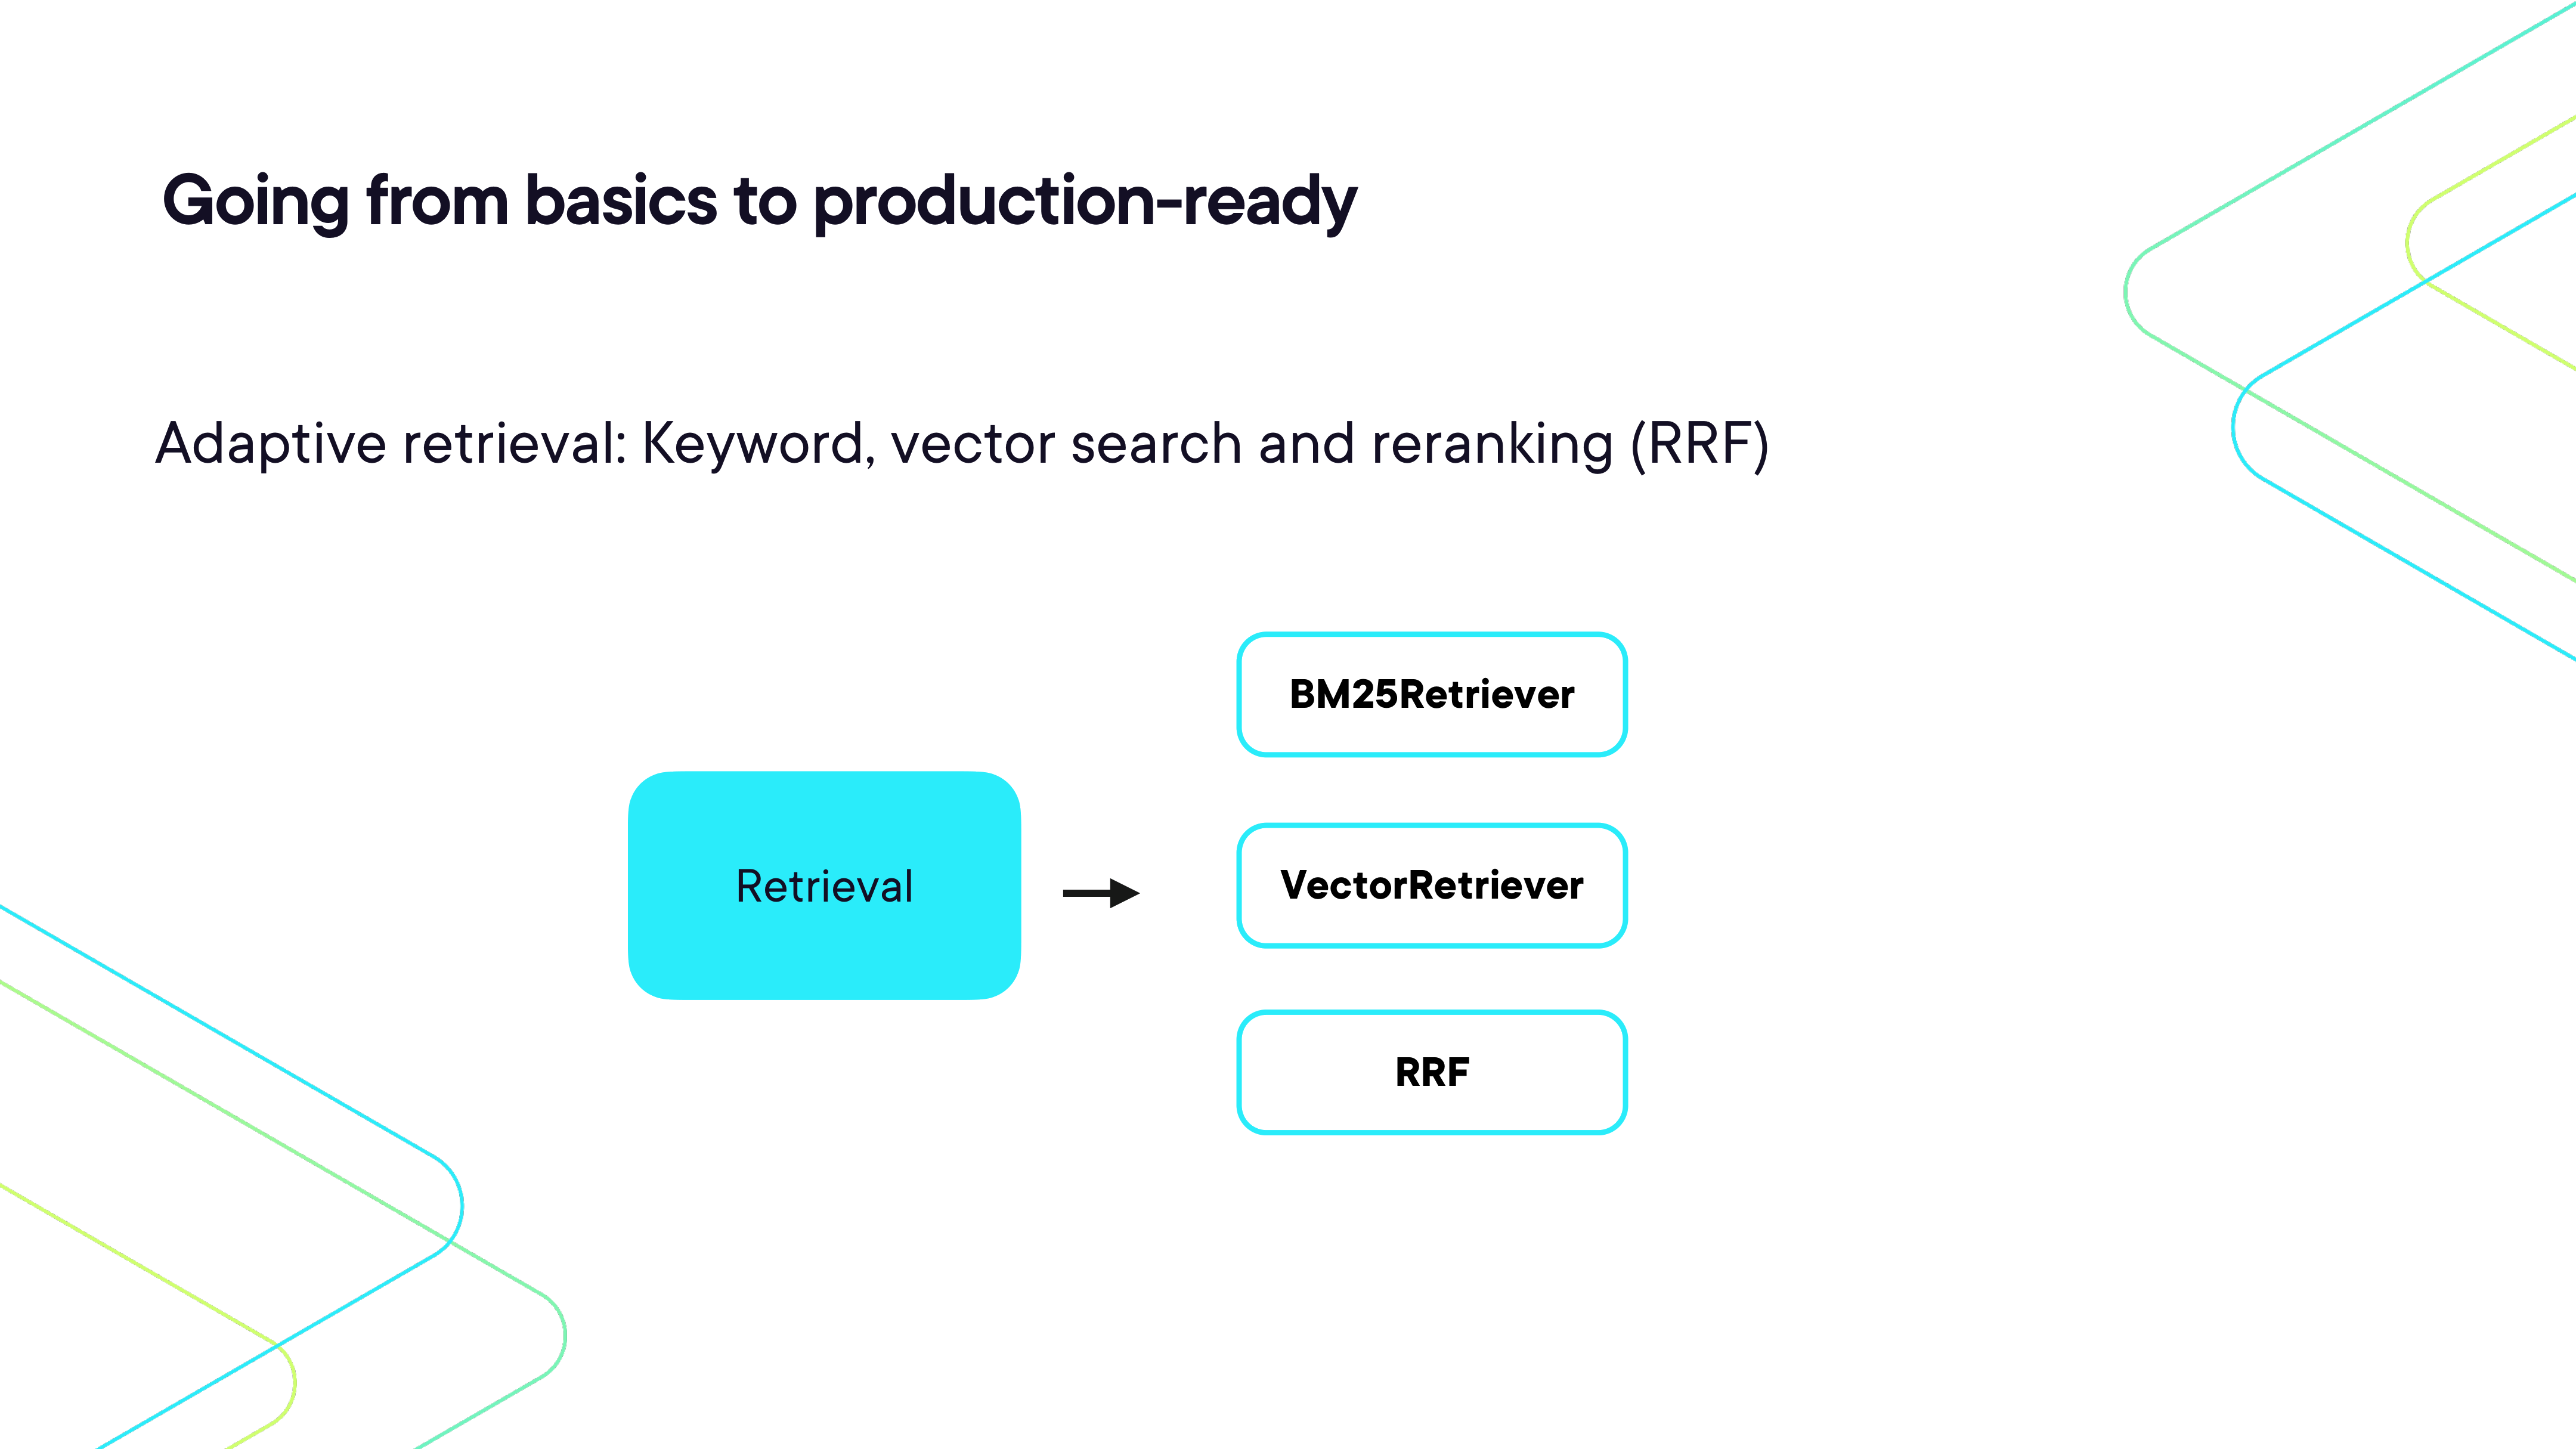

In [7]:
render_diagram(Path("assets/06-adaptive-retrieval-bm25-vector.png"))

### Demo: Building a Production-Ready RAG System (exercises 2.1–2.2)

A full production-ready RAG pipeline integrating:
- Query rewriting and decomposition
- Query routing and classification (HyDE + step-back)
- Adaptive retrieval: BM25 + vector search
- Reciprocal Rank Fusion (RRF)
- Context window management: pruning and summarising
- Context assembly and LLM generation

**Stack:** LlamaIndex · OpenAI/Cohere API · LangSmith

See [`02-enterprise-rag-demos/2.1/`](02-enterprise-rag-demos/2.1/) for query transformation and routing, and [`02-enterprise-rag-demos/2.2/`](02-enterprise-rag-demos/2.2/) for fine-tuning retrieval and reranking with RRF.

---
<a id="module-03"></a>
## Module 03: Optimizing Context and Memory Management

_Distinguishes retrieval from memory, introduces the three memory types (episodic, semantic, procedural), and builds a production RAG system with short- and long-term memory augmentation._

### Retrieval vs. Memory

| | Retrieval | Memory |
|---|---|---|
| Nature | External knowledge access | Internal knowledge persistence |
| Scope | On-demand lookup from a corpus | Accumulated and maintained across interactions |
| Storage | Vector DB, search index | Conversation history, Vector DB, system state |

Retrieval fetches knowledge from outside the model on demand; memory stores and persists knowledge across turns or sessions.

### Memory Types

AI systems draw on three distinct memory types, mirroring cognitive memory theory:


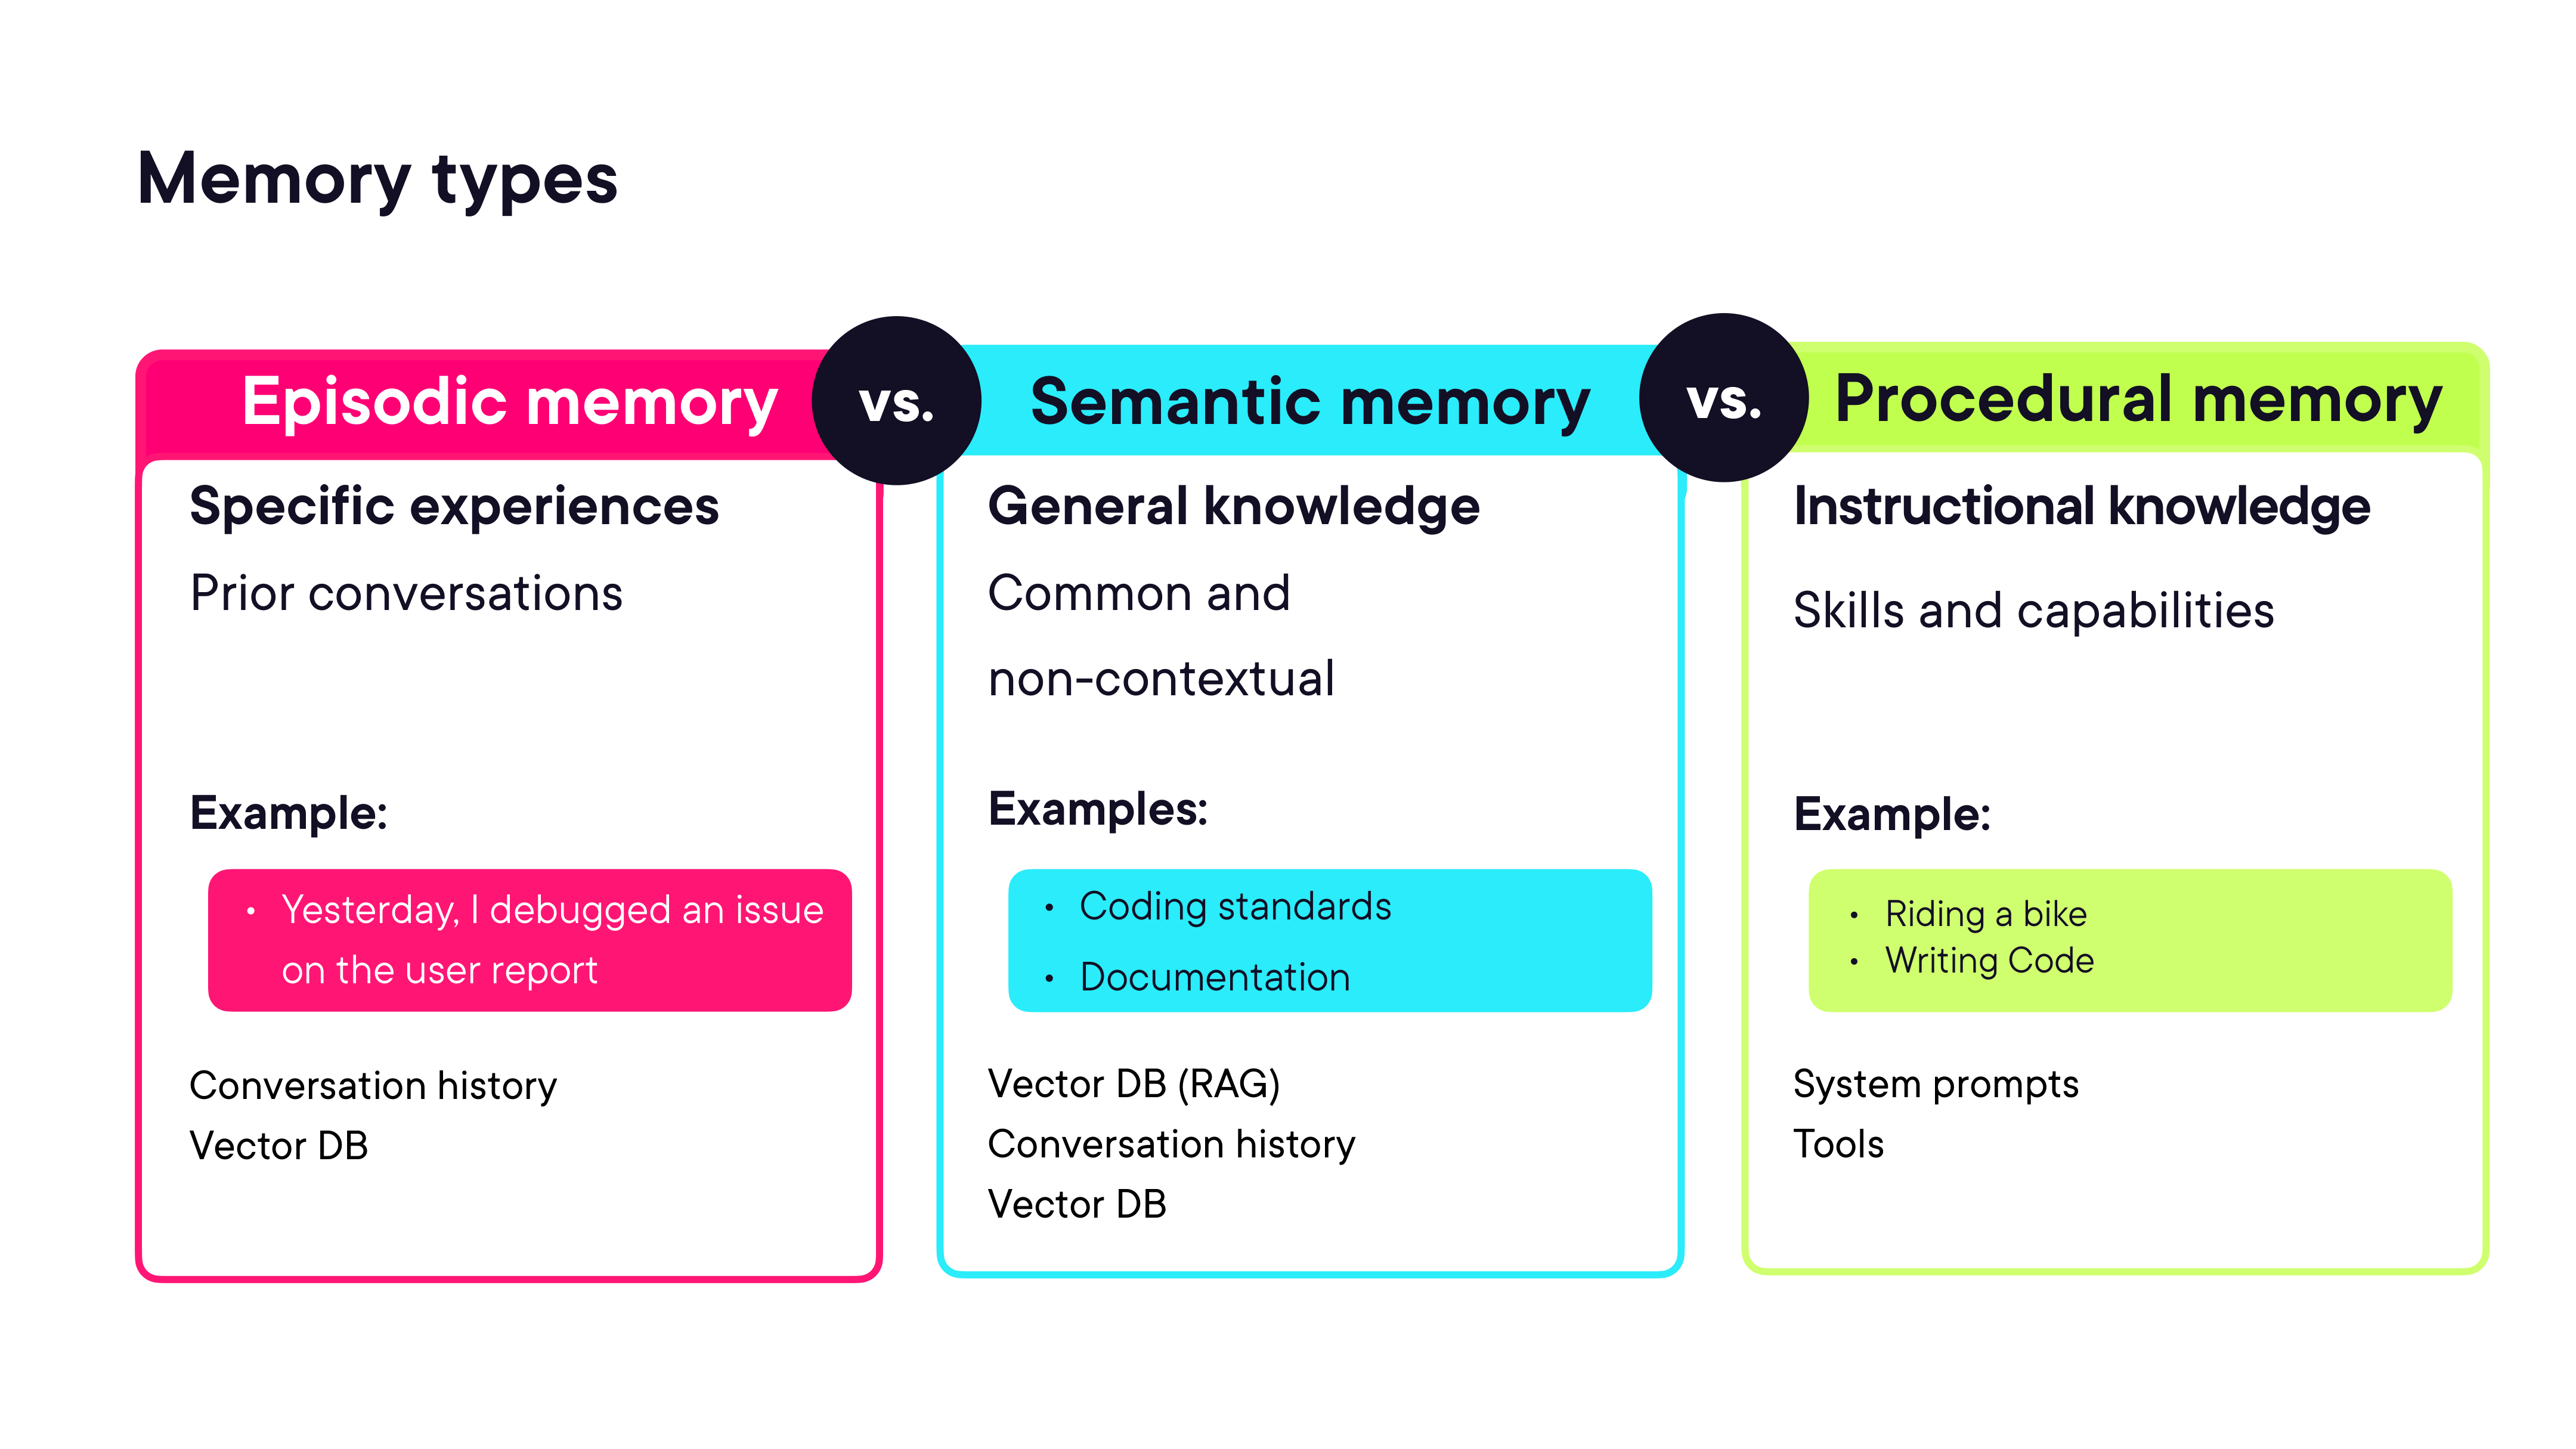

In [8]:
render_diagram(Path("assets/07-memory-types-diagram.png"))

| Memory Type | Nature | Examples | Implementation |
|---|---|---|---|
| **Episodic** | Specific experiences and prior conversations | *"Yesterday I debugged the user report issue"* | Conversation history, Vector DB |
| **Semantic** | General, non-contextual knowledge | Coding standards, documentation | Vector DB (RAG), Conversation history |
| **Procedural** | Instructional knowledge — skills and capabilities | *"Act as a senior AI engineer"*, riding a bike, writing code | System prompts, Tools |

In practice:
- **Short-term memory** maps to episodic: a sliding window of recent turns, often backed by Redis with a TTL
- **Long-term memory** maps to semantic: a persistent vector store (e.g. Qdrant) that survives session boundaries
- **Procedural memory** is injected at the system prompt level and defines how the agent behaves

### Demo: Production-Ready RAG with Memory Augmentation

Extends the enterprise RAG pipeline with full memory management:
- Query transformation and expansion
- Hybrid search and multi-stage retrieval
- LLM-based reranking and fusion
- Short-term memory (Redis TTL-backed sliding window)
- Long-term memory (Qdrant distributed vector store)
- Memory pruning and summarisation
- LLM generation and final answer

See [`03-context-memory-demos/start/`](03-context-memory-demos/start/) and [`03-context-memory-demos/end/`](03-context-memory-demos/end/) for the full project.

---
<a id="module-04"></a>
## Module 04: Caching, Optimizing, and Monitoring Performance

_Transitions the RAG pipeline to async execution, adds a caching layer, and addresses multi-user concurrency for enterprise-scale deployments._

### Scaling for Enterprise RAG

Moving from a synchronous prototype to a production system requires three additional capabilities:

- **Asynchronous processing** — decouple retrieval and generation from the request/response cycle; handle long-running queries without blocking
- **Multi-user concurrency control** — isolate sessions, manage shared resources, and prevent race conditions under concurrent load
- **Caching results** — store and reuse responses for identical or semantically similar queries to reduce latency and LLM API costs

### Transitioning to Async RAG

The async pipeline extends the full production RAG stack:

1. Query transformation and expansion
2. Hybrid search and multi-stage retrieval
3. LLM-based reranking and fusion
4. Short- and long-term memory management
5. Memory pruning and summarisation
6. LLM generation and final answer
7. **Caching layer** — semantic cache sits between the query and the retrieval/generation pipeline
8. **Async pipeline** — all stages run with `asyncio` for non-blocking, concurrent execution

### Caching Strategies

**Exact-match cache:** Store the full response keyed by the verbatim query string. Fast lookups, but only hits on identical queries.

**Semantic cache:** Embed the incoming query and compare against cached query embeddings. Return a cached response if cosine similarity exceeds a threshold. Handles paraphrased or synonymous queries.

**Cache invalidation:** Time-to-live (TTL) policies ensure stale knowledge-base updates are not served from cache indefinitely.

### Concurrency Control

Enterprise deployments must handle multiple simultaneous users:
- Session isolation: each user's memory context must not bleed into others'
- Rate limiting: prevent runaway token consumption from individual sessions
- Resource pooling: shared vector store and LLM client connections managed with async context managers

### Demo: Scaling RAG Systems — Async and Distributed

Transitions the full production RAG pipeline to async execution and adds a caching layer:
- Full query transformation, hybrid retrieval, reranking, and memory pipeline (from Module 03)
- Redis-backed semantic cache for query-level deduplication
- `asyncio`-based async pipeline for non-blocking concurrent processing
- Session-scoped memory isolation for multi-user scenarios

See [`04-caching-performance-demos/start/`](04-caching-performance-demos/start/) and [`04-caching-performance-demos/end/`](04-caching-performance-demos/end/) for the full project.